# Results notebook: SE-ResNet-26 (4.81M params) on the NYU Tandon DL F26 CIFAR-10 challenge

Team **Punters**: Uvindu Salgado (uis202@nyu.edu), Michael Wang (mzw2010@nyu.edu)

This notebook is the verification and analysis companion to the report. It does **no training**
(training ran on Kaggle T4 GPUs; the executed Kaggle notebooks are in `kaggle_runs/`). Instead it:

1. Prints the **parameter count** of every architecture we trained and checks the 5M budget.
2. Loads our checkpoints and **recomputes validation accuracy** on the seed-0 5,000-image split.
3. **Regenerates the two submitted prediction files** from the final checkpoints and checks they match what we uploaded.
4. Prints the **final test accuracy** (Kaggle scores) and the full ablation table.
5. Draws the figures used in the report: training curves, validation vs. leaderboard accuracy,
   the robustness scorecard, the train/test shift analysis, and leaderboard noise.

**To run:** put the competition files in `data/` (`train_labels.csv`, `test.csv`, `sample_submission.csv`,
`train_images/`, `test_images/`; see README). CPU is enough (about 15 minutes); a GPU is used automatically if present.

In [1]:
import os, re, glob, time, inspect, hashlib
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
import models

DATA = "data"
DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_grad_enabled(False)
os.makedirs("figures", exist_ok=True); os.makedirs("results/regenerated", exist_ok=True)
print("device:", DEV, "| torch", torch.__version__)

# One colour per run, used in every figure (categorical palette validated for colour-vision deficiency;
# the three headline models v2 / v4 / robust take the first three slots, which pass all-pairs checks).
COL = {"v2": "#2a78d6", "v4": "#eb6834", "robust": "#1baf7a", "v1": "#eda100",
       "v3_sam": "#e87ba4", "kd": "#008300", "mw_augmix": "#6250d6", "hardview": "#e34948"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 8.5, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "legend.frameon": False,
                     "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight", "lines.linewidth": 1.6})
def save(fig, name):
    fig.savefig(f"figures/{name}.pdf"); fig.savefig(f"figures/{name}.png")

device: cpu | torch 2.15.0+cu132


## 1. Parameter counts (budget: 5,000,000 trainable parameters)

In [2]:
# models.py is a verbatim copy of the model block in train.py (the script that trained the final models).
train_src = open("train.py").read()
block = train_src[train_src.index("class SE(nn.Module):"):train_src.index("def make_model(spec):")]
assert block in open("models.py").read(), "models.py drifted from train.py"
print("models.py model code is identical to train.py: OK\n")

archs = {
    "v1  ResNet-14 [80,160,320] x [2,2,2]":            models.ResNet([80, 160, 320], [2, 2, 2]),
    "v2  ResNet-24 [64,128,256] x [4,4,3]":            models.make_model("resnet-4-4-3"),
    "v4  SE-ResNet-26 [64,128,256] x [5,4,3]  (FINAL)": models.make_model("resnet-5-4-3-se"),
    "WRN-28-10 (considered as a teacher, never trained)": models.make_model("wrn-28-10"),
}
for name, m in archs.items():
    n = models.count_params(m)
    print(f"{name:52s} {n:>12,}  {'within budget' if n <= 5_000_000 else 'OVER 5M (not allowed as final model)'}")

final = models.make_model("resnet-5-4-3-se")
N_FINAL = models.count_params(final)
assert N_FINAL == 4_810_754 and N_FINAL <= 5_000_000
print(f"\nFINAL MODEL (both submissions): SE-ResNet-26, trainable parameters = {N_FINAL:,}")

# where the parameters live
rows = [("stem", final.stem)] + [(f"layers[{i}]", b) for i, b in enumerate(final.layers)] + [("fc", final.fc)]
stage = {"stem": 0}
for name, mod in rows:
    stage[name] = models.count_params(mod)
by_stage = {"stem (3x3 conv, 64)": stage["stem"],
            "stage 1: 5 blocks @ 64ch, 32x32": sum(stage[f"layers[{i}]"] for i in range(0, 5)),
            "stage 2: 4 blocks @ 128ch, 16x16": sum(stage[f"layers[{i}]"] for i in range(5, 9)),
            "stage 3: 3 blocks @ 256ch, 8x8": sum(stage[f"layers[{i}]"] for i in range(9, 12)),
            "global avg pool + fc (256->10)": stage["fc"]}
se_params = sum(models.count_params(b.se) for b in final.layers)
for k, v in by_stage.items():
    print(f"  {k:36s} {v:>10,}  ({100 * v / N_FINAL:4.1f}%)")
print(f"  of which squeeze-excitation gates: {se_params:,} ({100 * se_params / N_FINAL:.1f}%)")

models.py model code is identical to train.py: OK



v1  ResNet-14 [80,160,320] x [2,2,2]                    4,337,370  within budget
v2  ResNet-24 [64,128,256] x [4,4,3]                    4,697,162  within budget
v4  SE-ResNet-26 [64,128,256] x [5,4,3]  (FINAL)        4,810,754  within budget
WRN-28-10 (considered as a teacher, never trained)     36,479,194  OVER 5M (not allowed as final model)

FINAL MODEL (both submissions): SE-ResNet-26, trainable parameters = 4,810,754
  stem (3x3 conv, 64)                       1,856  ( 0.0%)
  stage 1: 5 blocks @ 64ch, 32x32         375,400  ( 7.8%)
  stage 2: 4 blocks @ 128ch, 16x16      1,125,152  (23.4%)
  stage 3: 3 blocks @ 256ch, 8x8        3,305,776  (68.7%)
  global avg pool + fc (256->10)            2,570  ( 0.1%)
  of which squeeze-excitation gates: 39,608 (0.8%)


## 2. Data and the seed-0 validation split

In [3]:
def load(folder, names):
    return np.stack([np.asarray(Image.open(os.path.join(DATA, folder, f)).convert("RGB")) for f in names])

cache = os.path.join(DATA, "_cache.npz")
train_df = pd.read_csv(f"{DATA}/train_labels.csv"); test_df = pd.read_csv(f"{DATA}/test.csv")
sample = pd.read_csv(f"{DATA}/sample_submission.csv")
if os.path.exists(cache):
    z = np.load(cache); X, Xte = z["X"], z["Xte"]
else:
    t = time.time(); X = load("train_images", train_df.filename); Xte = load("test_images", test_df.filename)
    np.savez(cache, X=X, Xte=Xte); print(f"decoded PNGs in {time.time() - t:.0f}s")
y = train_df.label.values
np.random.seed(0); perm = np.random.permutation(len(X))      # identical to train.py with --seed 0
val_idx, tr_idx = perm[:5000], perm[5000:]
print("train", X.shape, "| test", Xte.shape, "| val split", len(val_idx), "images, class counts", np.bincount(y[val_idx]))

def stats(idx):  # per-channel normalisation exactly as in train.py (float64)
    a = X[idx].reshape(-1, 3)
    return a.mean(0, dtype=np.float64) / 255, a.std(0, dtype=np.float64) / 255
NORM = {"45k": stats(tr_idx), "50k": stats(np.arange(len(X)))}

train (50000, 32, 32, 3) | test (2000, 32, 32, 3) | val split 5000 images, class counts [503 483 487 527 473 548 491 502 482 504]


## 3. Recompute validation accuracy from the checkpoints

In [4]:
def predict(net, X_u8, norm, tta=False, bs=500):
    # Same as train.py: mean softmax over flips (and +-2px shifts when tta=True, i.e. 10 views)
    mean = torch.tensor(norm[0], dtype=torch.float32, device=DEV).view(1, 3, 1, 1)
    std = torch.tensor(norm[1], dtype=torch.float32, device=DEV).view(1, 3, 1, 1)
    net = net.to(DEV).eval(); out = []
    shifts = [(0, 0), (2, 0), (-2, 0), (0, 2), (0, -2)] if tta else [(0, 0)]
    for k in range(0, len(X_u8), bs):
        x = torch.from_numpy(X_u8[k:k + bs]).to(DEV).permute(0, 3, 1, 2).float().div(255)
        xp = F.pad((x - mean) / std, (2, 2, 2, 2), mode="reflect"); p = 0
        for dy, dx in shifts:
            v = xp[:, :, 2 + dy:34 + dy, 2 + dx:34 + dx]
            p = p + net(v).softmax(1) + net(v.flip(3)).softmax(1)
        out.append(p / (2 * len(shifts)))
    return torch.cat(out).cpu().numpy()

def load_ckpt(spec, path):
    m = models.make_model(spec); m.load_state_dict(torch.load(path, map_location="cpu")); return m

runs = pd.read_csv("results/runs.csv").set_index("run")
val_ckpts = {"v2": ("resnet-4-4-3", "checkpoints/v2.pt"),
             "v4_val": ("resnet-5-4-3-se", "checkpoints/v4_val.pt"),
             "robust_val": ("resnet-5-4-3-se", "checkpoints/robust_val.pt")}
recomputed = {}
for run, (spec, path) in val_ckpts.items():
    t = time.time()
    acc = (predict(load_ckpt(spec, path), X[val_idx], NORM["45k"]).argmax(1) == y[val_idx]).mean()
    recomputed[run] = acc
    print(f"{run:11s} val accuracy (flip-averaged, EMA weights) = {acc:.4f}   "
          f"[logged on Kaggle GPU: {runs.loc[run, 'val_flip']:.4f}]   {time.time() - t:.0f}s")

v2          val accuracy (flip-averaged, EMA weights) = 0.9740   [logged on Kaggle GPU: 0.9740]   85s


v4_val      val accuracy (flip-averaged, EMA weights) = 0.9790   [logged on Kaggle GPU: 0.9790]   99s


robust_val  val accuracy (flip-averaged, EMA weights) = 0.9782   [logged on Kaggle GPU: 0.9782]   99s


## 4. Regenerate the two submitted files from the final checkpoints

In [5]:
finals = {"v4_full": "checkpoints/v4_full.pt", "robust_full": "checkpoints/robust_full.pt"}
for run, path in finals.items():
    t = time.time()
    probs = predict(load_ckpt("resnet-5-4-3-se", path), Xte, NORM["50k"], tta=True)
    pred = dict(zip(test_df.id.values, probs.argmax(1)))
    sub = pd.DataFrame({"id": sample.id.values, "label": [int(pred[i]) for i in sample.id.values]})
    sub.to_csv(f"results/regenerated/{run}.csv", index=False)
    uploaded = pd.read_csv(f"results/submissions/{run}.csv")
    agree = (uploaded.label.values == sub.label.values).mean()
    print(f"{run:12s} regenerated {len(sub)} predictions | agreement with uploaded file: {agree:.4f} "
          f"({int(round((1 - agree) * len(sub)))} of {len(sub)} differ; GPU fp16 vs CPU fp32) | {time.time() - t:.0f}s")

v4_full      regenerated 2000 predictions | agreement with uploaded file: 1.0000 (0 of 2000 differ; GPU fp16 vs CPU fp32) | 201s


robust_full  regenerated 2000 predictions | agreement with uploaded file: 0.9995 (1 of 2000 differ; GPU fp16 vs CPU fp32) | 198s


## 5. Final test accuracy and the full ablation table

In [6]:
show = runs.reset_index()[["order", "run", "author", "arch", "params", "epochs", "train_images", "val_flip",
                           "val_10view", "public", "private", "final_pick"]].sort_values("order")
pd.set_option("display.width", 200, "display.max_colwidth", 40)
print(show.to_string(index=False))
print("\nval_* : accuracy on our 5,000-image held-out split (runs with train_images=50000 have no val split;"
      "\n        their twin run with the same recipe on 45k images is the row above).")
print("public / private : Kaggle accuracy on the two halves (1,000 images each) of the hidden test set.")
print("v3_full and v3_sam were uploaded from the same notebook version; which scored 0.890 vs 0.893 was not recorded.\n")
for run in ["v4_full", "robust_full"]:
    r = runs.loc[run]
    priv = "pending (released after the deadline)" if pd.isna(r.private) else f"{float(r.private):.3f}"
    print(f"FINAL TEST ACCURACY  {run:12s} public = {float(r.public):.3f} | private = {priv} | params = {int(r.params):,}")

 order         run author                              arch  params  epochs  train_images  val_flip  val_10view      public  private final_pick
     1          v1     US       ResNet [80,160,320]x[2,2,2] 4337370     200         45000    0.9666         NaN       0.869      NaN         no
     2          v2     US    ResNet-24 [64,128,256]x[4,4,3] 4697162     300         45000    0.9740      0.9754       0.899      NaN         no
     3     v3_full     US    ResNet-24 [64,128,256]x[4,4,3] 4697162     300         50000       NaN         NaN 0.890|0.893      NaN         no
     4      v3_sam     US    ResNet-24 [64,128,256]x[4,4,3] 4697162     200         45000    0.9722      0.9720 0.893|0.890      NaN         no
     5   mw_augmix     MW    ResNet-24 [64,128,256]x[4,4,3] 4697162     300         45000    0.9720      0.9730       0.894      NaN         no
     6   mw_v2full     MW    ResNet-24 [64,128,256]x[4,4,3] 4697162     300         50000       NaN         NaN       0.898      NaN    

## 6. Training curves

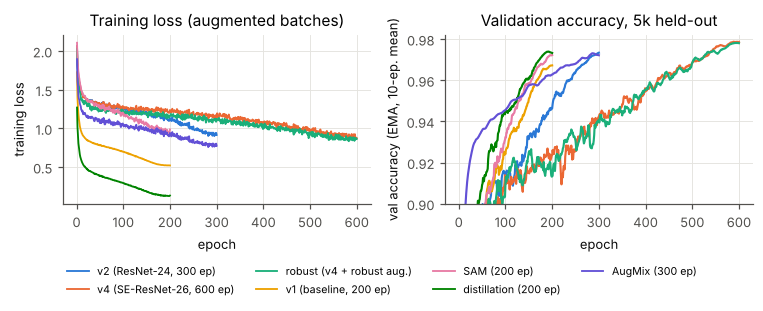

Loss levels differ across recipes because CutMix, label smoothing and distillation change the target; compare shapes, not heights. v1 has no EMA and its loss is on easier (weakly augmented) batches.


In [7]:
def log(run):
    return pd.read_csv(f"results/logs/{run}/train_log.csv")

curve_runs = [("v2", "v2", "v2 (ResNet-24, 300 ep)"), ("v4_val", "v4", "v4 (SE-ResNet-26, 600 ep)"),
              ("robust_val", "robust", "robust (v4 + robust aug.)"), ("v1", "v1", "v1 (baseline, 200 ep)"),
              ("v3_sam", "v3_sam", "SAM (200 ep)"), ("kd_val", "kd", "distillation (200 ep)"),
              ("mw_augmix", "mw_augmix", "AugMix (300 ep)")]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.0, 2.75))
for run, c, label in curve_runs:
    d = log(run); col = "val_acc_ema" if "val_acc_ema" in d else "val_acc"
    a1.plot(d.epoch, d.train_loss, color=COL[c], lw=1.2, label=label)
    smooth = d[col].rolling(10, min_periods=1, center=True).mean()     # 10-epoch rolling mean for readability
    a2.plot(d.epoch, smooth, color=COL[c], lw=1.4, label=label)
a1.set(xlabel="epoch", ylabel="training loss", title="Training loss (augmented batches)")
a2.set(xlabel="epoch", ylabel="val accuracy (EMA, 10-ep. mean)", title="Validation accuracy, 5k held-out", ylim=(0.90, 0.982))
h, l = a1.get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, fontsize=7, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.11, 1, 1)); save(fig, "fig_curves"); plt.show()
print("Loss levels differ across recipes because CutMix, label smoothing and distillation change the target;"
      " compare shapes, not heights. v1 has no EMA and its loss is on easier (weakly augmented) batches.")

## 7. Validation accuracy vs. leaderboard accuracy

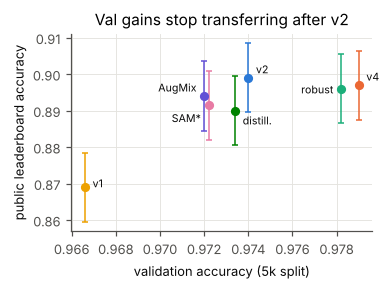

error bars: +-1 s.e. = 0.0095 (binomial, n=1000). *SAM vs full-data: 0.890/0.893, midpoint shown.


In [8]:
# Full-data runs have no val split; we pair them with their 45k twin (same recipe).
pts = [("v1", "v1", 0.9666, 0.869), ("v2", "v2", 0.9740, 0.899), ("SAM*", "v3_sam", 0.9722, 0.8915),
       ("AugMix", "mw_augmix", 0.9720, 0.894), ("distill.", "kd", 0.9734, 0.890), ("v4", "v4", 0.9790, 0.897),
       ("robust", "robust", 0.9782, 0.896)]
se = np.sqrt(0.9 * 0.1 / 1000)                         # binomial s.e. of a score on 1,000 images
fig, ax = plt.subplots(figsize=(3.6, 2.7))
off = {"v1": (5, 0, "left"), "v2": (5, 3, "left"), "SAM*": (-5, -11, "right"), "AugMix": (-5, 3, "right"),
       "distill.": (5, -9, "left"), "v4": (5, 3, "left"), "robust": (-5, -3, "right")}
for name, c, v, p in pts:
    ax.errorbar(v, p, yerr=se, fmt="o", ms=5, color=COL[c], ecolor=COL[c], elinewidth=1, capsize=2)
    dx, dy, ha = off[name]
    ax.annotate(name, (v, p), xytext=(dx, dy), textcoords="offset points", fontsize=7, color=INK, ha=ha)
ax.set(xlabel="validation accuracy (5k split)", ylabel="public leaderboard accuracy",
       title="Val gains stop transferring after v2")
fig.tight_layout(); save(fig, "fig_val_vs_public"); plt.show()
print(f"error bars: +-1 s.e. = {se:.4f} (binomial, n=1000). *SAM vs full-data: 0.890/0.893, midpoint shown.")

## 8. Robustness scorecard (shifted copies of our own validation images)

         clean  bright+15%  contrast+25%  sharpen x2  blur s0.7  grayscale  jpeg q60  noise 0.04  shifted-mean
v2      0.9740      0.9722        0.9710      0.9672     0.9428     0.9520    0.8386      0.9116        0.9365
v4      0.9790      0.9774        0.9776      0.9742     0.9568     0.9580    0.8270      0.9280        0.9427
robust  0.9782      0.9780        0.9768      0.9726     0.9744     0.9588    0.8504      0.9298        0.9487


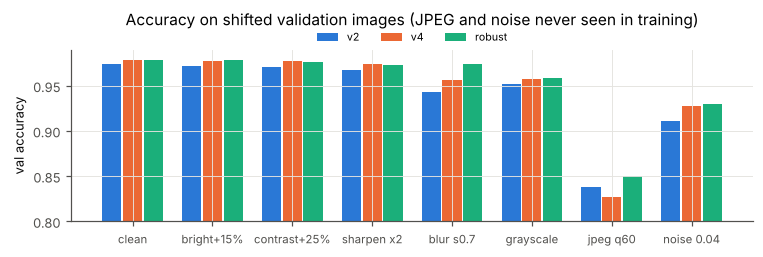


MW AugMix run, 7-corruption benchmark (EMA, val acc):
           set  val_acc
         clean   0.9720
gaussian_noise   0.7392
 gaussian_blur   0.9550
      pixelate   0.4196
          jpeg   0.6776
    brightness   0.9426
      contrast   0.9256
      saturate   0.9640
  corrupt_mean   0.8034


In [9]:
pat = re.compile(r"SCORECARD (\S+ \S+)\s.*?clean ([\d.]+) \| shifted-mean ([\d.]+) \| (.*)")
score = {}
for line in open("results/logs/robust_val/stdout.log"):
    m = pat.search(line)
    if m:
        kv = re.findall(r"(\S+(?: x2| s0\.7| q60| 0\.04|\+\d+%)?) ([\d.]+)", m.group(4))
        score[m.group(1)] = {"clean": float(m.group(2)), **{k: float(v) for k, v in kv}, "shifted-mean": float(m.group(3))}
sc = pd.DataFrame(score).T.rename(index={"ref resnet-4-4-3": "v2", "ref resnet-5-4-3-se": "v4",
                                          "NEW resnet-5-4-3-se": "robust"}).loc[["v2", "v4", "robust"]]
print(sc.round(4).to_string()); sc.to_csv("results/robustness_scorecard.csv")

conds = [c for c in sc.columns if c not in ("clean", "shifted-mean")]
xs = np.arange(len(conds) + 1); w = 0.26
fig, ax = plt.subplots(figsize=(7.0, 2.4))
for i, run in enumerate(["v2", "v4", "robust"]):
    vals = [sc.loc[run, "clean"]] + [sc.loc[run, c] for c in conds]
    ax.bar(xs + (i - 1) * w, vals, width=w - 0.02, color=COL[run], label=run)
ax.set_xticks(xs, ["clean"] + conds, fontsize=7.5); ax.set_ylim(0.80, 0.99)
ax.set(ylabel="val accuracy")
ax.set_title("Accuracy on shifted validation images (JPEG and noise never seen in training)", pad=16)
ax.legend(ncol=3, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0), borderaxespad=0.2)
fig.tight_layout(); save(fig, "fig_scorecard"); plt.show()

mw = pd.read_csv("results/logs/mw_augmix/robustness.csv")
print("\nMW AugMix run, 7-corruption benchmark (EMA, val acc):")
print(mw[mw.net == "ema"][["set", "val_acc"]].round(4).to_string(index=False))

## 9. How the hidden test images differ from the training images (no labels used)

                          train (50k)  test (2k)  test / train
mean intensity                 0.4734     0.4907        1.0365
per-image contrast (std)       0.2110     0.2197        1.0408
edge energy (mean |dx|)        0.0540     0.0586        1.0847
fraction grayscale             0.0112     0.0330        2.9359


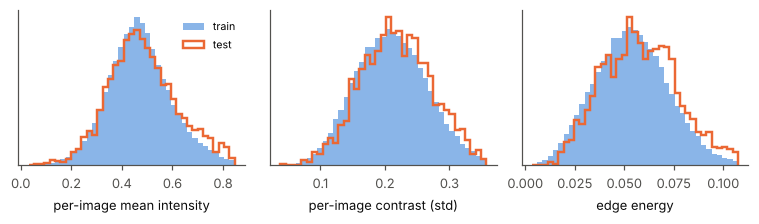

In [10]:
def img_stats(A, chunk=5000):
    out = {"mean": [], "contrast": [], "edge": [], "gray": []}
    for k in range(0, len(A), chunk):      # float64 in chunks (float32 sums over 150M values lose precision)
        a = A[k:k + chunk].astype(np.float64) / 255
        out["mean"].append(a.mean((1, 2, 3))); out["contrast"].append(a.std((1, 2, 3)))
        out["edge"].append(np.abs(np.diff(a, axis=2)).mean((1, 2, 3)))
        out["gray"].append((np.abs(a[..., 0] - a[..., 1]).max((1, 2)) < 1e-9) & (np.abs(a[..., 1] - a[..., 2]).max((1, 2)) < 1e-9))
    return {k: np.concatenate(v) for k, v in out.items()}
S_tr, S_te = img_stats(X), img_stats(Xte)
tab = pd.DataFrame({
    "train (50k)": [S_tr["mean"].mean(), S_tr["contrast"].mean(), S_tr["edge"].mean(), S_tr["gray"].mean()],
    "test (2k)": [S_te["mean"].mean(), S_te["contrast"].mean(), S_te["edge"].mean(), S_te["gray"].mean()]},
    index=["mean intensity", "per-image contrast (std)", "edge energy (mean |dx|)", "fraction grayscale"])
tab["test / train"] = tab["test (2k)"] / tab["train (50k)"]
print(tab.round(4).to_string()); tab.to_csv("results/test_shift_stats.csv")

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.1))
for ax, key, lab in zip(axs, ["mean", "contrast", "edge"], ["per-image mean intensity", "per-image contrast (std)", "edge energy"]):
    bins = np.linspace(min(S_tr[key].min(), S_te[key].min()), np.percentile(np.r_[S_tr[key], S_te[key]], 99.5), 40)
    ax.hist(S_tr[key], bins=bins, density=True, color=COL["v2"], alpha=0.55, label="train")
    ax.hist(S_te[key], bins=bins, density=True, histtype="step", lw=1.6, color=COL["v4"], label="test")
    ax.set(xlabel=lab, yticks=[]); ax.grid(False)
axs[0].legend(fontsize=7)
fig.tight_layout(); save(fig, "fig_shift"); plt.show()

## 10. How noisy is a 1,000-image leaderboard? (prediction agreement between our submissions)

In [11]:
subs = ["v2", "v3_full", "v3_sam", "mw_augmix", "mw_v2full", "kd_full", "v4_full", "robust_full"]
P = {r: pd.read_csv(f"results/submissions/{r}.csv").sort_values("id").label.values for r in subs}
D = pd.DataFrame([[(P[a] != P[b]).mean() for b in subs] for a in subs], index=subs, columns=subs)
print("fraction of the 2,000 test images on which two submissions disagree:")
print((100 * D).round(1).to_string())
off = D.values[np.triu_indices(len(subs), 1)]
d = np.median(off)
print(f"\nmedian pairwise disagreement: {100 * d:.1f}% of test images")
print(f"If two models are equally accurate, each disagreement is a coin flip for which one is right, so their"
      f"\ndifference on the 1,000 public images has s.d. ~ sqrt(d/1000) = {np.sqrt(d / 1000):.4f}"
      f" ({100 * np.sqrt(d / 1000):.1f} points).")
print("Our public scores since v2 span 0.890-0.899: a spread consistent with that noise level.")

fraction of the 2,000 test images on which two submissions disagree:
              v2  v3_full  v3_sam  mw_augmix  mw_v2full  kd_full  v4_full  robust_full
v2           0.0      5.9     6.6        7.0        6.8      5.3      5.6          6.4
v3_full      5.9      0.0     5.9        7.4        6.0      5.1      5.8          6.5
v3_sam       6.6      5.9     0.0        7.4        6.1      4.4      6.4          7.0
mw_augmix    7.0      7.4     7.4        0.0        6.7      6.4      6.9          6.4
mw_v2full    6.8      6.0     6.1        6.7        0.0      4.8      5.9          6.8
kd_full      5.3      5.1     4.4        6.4        4.8      0.0      5.4          5.4
v4_full      5.6      5.8     6.4        6.9        5.9      5.4      0.0          5.9
robust_full  6.4      6.5     7.0        6.4        6.8      5.4      5.9          0.0

median pairwise disagreement: 6.2% of test images
If two models are equally accurate, each disagreement is a coin flip for which one is right, so t

## Summary

In [12]:
print(f"Final model: SE-ResNet-26 (ResNet, widths 64/128/256, blocks 5/4/3, squeeze-excitation), {N_FINAL:,} trainable params")
print(f"Validation accuracy (5k held-out, recomputed here): v4 {recomputed['v4_val']:.4f} | robust {recomputed['robust_val']:.4f} | v2 {recomputed['v2']:.4f}")
for run in ["v4_full", "robust_full"]:
    r = runs.loc[run]; priv = "pending" if pd.isna(r.private) else f"{float(r.private):.3f}"
    print(f"Kaggle test accuracy, {run}: public {float(r.public):.3f}, private {priv}")

Final model: SE-ResNet-26 (ResNet, widths 64/128/256, blocks 5/4/3, squeeze-excitation), 4,810,754 trainable params
Validation accuracy (5k held-out, recomputed here): v4 0.9790 | robust 0.9782 | v2 0.9740
Kaggle test accuracy, v4_full: public 0.897, private pending
Kaggle test accuracy, robust_full: public 0.896, private pending
